###Câu a) Đọc bộ dữ liệu MNIST

In [ ]:
def in_thong_tin():
    print("Họ và tên: Nguyễn Gia Huy")
    print("Mã sinh viên: 6451071027")
    print("-" * 30)

in_thong_tin()

from tensorflow.keras.datasets import mnist

(train_images, train_labels), (test_images, test_labels) = mnist.load_data()
print("Đã đọc xong dữ liệu MNIST")

Họ và tên: Nguyễn Gia Huy
Mã sinh viên: 6451071027
------------------------------
11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Đã đọc xong dữ liệu MNIST


###Câu b) In kích thước tập train, test

In [ ]:
in_thong_tin()

print("train_images:", train_images.shape)   # (60000, 28, 28)
print("train_labels:", train_labels.shape)   # (60000,)
print("test_images :", test_images.shape)    # (10000, 28, 28)
print("test_labels :", test_labels.shape)    # (10000,)

Họ và tên: Nguyễn Gia Huy
Mã sinh viên: 6451071027
------------------------------
train_images: (60000, 28, 28)
train_labels: (60000,)
test_images : (10000, 28, 28)
test_labels : (10000,)


###Câu c) Chuẩn hóa pixel về [0,1]

In [ ]:
in_thong_tin()

train_images = train_images / 255.0
test_images = test_images / 255.0

print("Min/Max train:", train_images.min(), train_images.max())
print("Min/Max test :", test_images.min(), test_images.max())

Họ và tên: Nguyễn Gia Huy
Mã sinh viên: 6451071027
------------------------------
Min/Max train: 0.0 1.0
Min/Max test : 0.0 1.0


###Câu d) Định nghĩa hàm create_model

In [ ]:
in_thong_tin()
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Flatten, Dense, Dropout, Input

def create_model():
    model = Sequential([
        Input(shape=(28, 28)),
        Flatten(),                              # 28x28 -> 784
        Dense(128, activation='relu'),
        Dropout(0.2),
        Dense(10, activation='softmax')
    ])
    model.compile(optimizer='adam',
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])
    return model

create_model().summary()

Họ và tên: Nguyễn Gia Huy
Mã sinh viên: 6451071027
------------------------------


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

###Câu e) Huấn luyện bằng k-fold cross validation (k = 10)

In [ ]:
in_thong_tin()
import numpy as np
from sklearn.model_selection import KFold

kfold = KFold(n_splits=10, shuffle=True, random_state=42)

models = []
accuracy_per_fold = []
loss_per_fold = []

fold_no = 1
for train_index, val_index in kfold.split(train_images):
    print(f"\n===== Fold {fold_no}/10 =====")

    model = create_model()

    X_train_fold, X_val_fold = train_images[train_index], train_images[val_index]
    y_train_fold, y_val_fold = train_labels[train_index], train_labels[val_index]

    model.fit(X_train_fold, y_train_fold,
              validation_data=(X_val_fold, y_val_fold),
              epochs=5, batch_size=32, verbose=1)

    models.append(model)

    loss, accuracy = model.evaluate(X_val_fold, y_val_fold, verbose=0)
    loss_per_fold.append(loss)
    accuracy_per_fold.append(accuracy)
    print(f"Fold {fold_no}: loss = {loss:.4f} | accuracy = {accuracy:.4f}")

    fold_no += 1

Họ và tên: Nguyễn Gia Huy
Mã sinh viên: 6451071027
------------------------------

===== Fold 1/10 =====
Epoch 1/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - accuracy: 0.9104 - loss: 0.3078 - val_accuracy: 0.9575 - val_loss: 0.1450
Epoch 2/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9568 - loss: 0.1480 - val_accuracy: 0.9667 - val_loss: 0.1054
Epoch 3/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9672 - loss: 0.1106 - val_accuracy: 0.9738 - val_loss: 0.0842
Epoch 4/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 9s 3ms/step - accuracy: 0.9725 - loss: 0.0898 - val_accuracy: 0.9748 - val_loss: 0.0823
Epoch 5/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9762 - loss: 0.0784 - val_accuracy: 0.9783 - val_loss: 0.0692
Fold 1: loss = 0.0692 | accuracy = 0.9783

===== Fold 2/10 =====
Epoch 1/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9106 - loss: 0.3082 - val_accuracy: 0.9540 - val_loss: 0.1583
Epoch 2/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - 

###Câu f) Mean và độ lệch chuẩn của Accuracy, Loss

In [ ]:
in_thong_tin()

print("Accuracy từng fold:", np.round(accuracy_per_fold, 4))
print("Loss từng fold    :", np.round(loss_per_fold, 4))
print(f"Mean Accuracy: {np.mean(accuracy_per_fold):.4f}")
print(f"Std Accuracy : {np.std(accuracy_per_fold):.4f}")
print(f"Mean Loss    : {np.mean(loss_per_fold):.4f}")
print(f"Std Loss     : {np.std(loss_per_fold):.4f}")

Họ và tên: Nguyễn Gia Huy
Mã sinh viên: 6451071027
------------------------------
Accuracy từng fold: [0.9783 0.976  0.9755 0.9778 0.9723 0.9775 0.9755 0.9747 0.9717 0.9753]
Loss từng fold    : [0.0692 0.0818 0.0845 0.077  0.0932 0.0755 0.0876 0.0809 0.0914 0.0826]
Mean Accuracy: 0.9755
Std Accuracy : 0.0021
Mean Loss    : 0.0824
Std Loss     : 0.0069


###Câu g) Biểu đồ accuracy, loss sau mỗi fold

Họ và tên: Nguyễn Gia Huy
Mã sinh viên: 6451071027
------------------------------


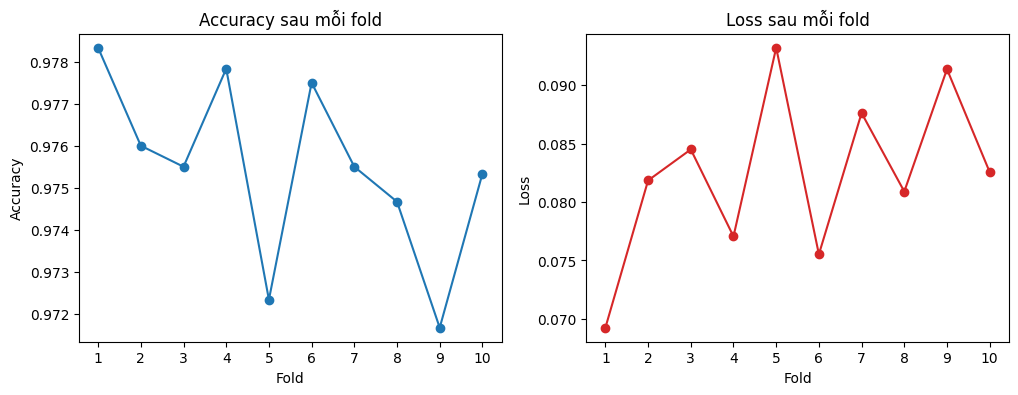

In [ ]:
in_thong_tin()
import matplotlib.pyplot as plt

folds = range(1, 11)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].plot(folds, accuracy_per_fold, marker='o')
ax[0].set_title('Accuracy sau mỗi fold')
ax[0].set_xlabel('Fold'); ax[0].set_ylabel('Accuracy')
ax[0].set_xticks(list(folds))

ax[1].plot(folds, loss_per_fold, marker='o', color='tab:red')
ax[1].set_title('Loss sau mỗi fold')
ax[1].set_xlabel('Fold'); ax[1].set_ylabel('Loss')
ax[1].set_xticks(list(folds))

plt.show()

###Câu h) Chọn mô hình tốt nhất và phân lớp tập test

In [ ]:
in_thong_tin()

best_index = np.argmax(accuracy_per_fold)
best_model = models[best_index]
print(f"Mô hình tốt nhất: fold {best_index + 1} "
      f"(accuracy = {accuracy_per_fold[best_index]:.4f})")

y_prob = best_model.predict(test_images)
y_pred = np.argmax(y_prob, axis=1)

print("10 nhãn dự đoán đầu:", y_pred[:10])
print("10 nhãn thực tế đầu:", test_labels[:10])

Họ và tên: Nguyễn Gia Huy
Mã sinh viên: 6451071027
------------------------------
Mô hình tốt nhất: fold 1 (accuracy = 0.9783)
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
10 nhãn dự đoán đầu: [7 2 1 0 4 1 4 9 5 9]
10 nhãn thực tế đầu: [7 2 1 0 4 1 4 9 5 9]


###Câu i) Accuracy trên tập test

In [ ]:
in_thong_tin()
from sklearn.metrics import accuracy_score

print("Accuracy trên tập test:", accuracy_score(test_labels, y_pred))

Họ và tên: Nguyễn Gia Huy
Mã sinh viên: 6451071027
------------------------------
Accuracy trên tập test: 0.9761


###Câu j) Precision, Recall, F1-score

In [ ]:
in_thong_tin()
from sklearn.metrics import classification_report

print(classification_report(test_labels, y_pred, digits=4))

Họ và tên: Nguyễn Gia Huy
Mã sinh viên: 6451071027
------------------------------
              precision    recall  f1-score   support

           0     0.9838    0.9888    0.9863       980
           1     0.9903    0.9850    0.9876      1135
           2     0.9767    0.9748    0.9758      1032
           3     0.9714    0.9743    0.9728      1010
           4     0.9855    0.9695    0.9774       982
           5     0.9667    0.9753    0.9710       892
           6     0.9841    0.9687    0.9763       958
           7     0.9748    0.9776    0.9762      1028
           8     0.9642    0.9692    0.9667       974
           9     0.9619    0.9762    0.9690      1009

    accuracy                         0.9761     10000
   macro avg     0.9759    0.9759    0.9759     10000
weighted avg     0.9762    0.9761    0.9761     10000



###Câu k) Confusion matrix bằng heatmap

Họ và tên: Nguyễn Gia Huy
Mã sinh viên: 6451071027
------------------------------


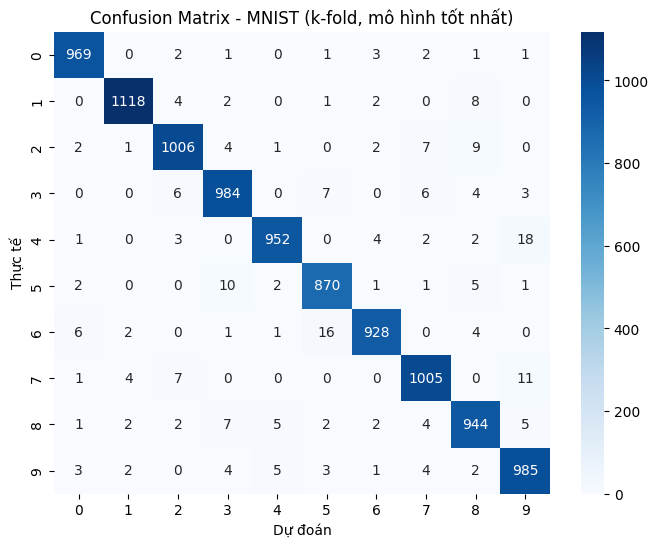

In [ ]:
in_thong_tin()
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(test_labels, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=range(10), yticklabels=range(10))
plt.xlabel('Dự đoán'); plt.ylabel('Thực tế')
plt.title('Confusion Matrix - MNIST (k-fold, mô hình tốt nhất)')
plt.show()

###Câu l) Kết quả phân lớp của 5 ảnh đầu tiên trong tập test

Họ và tên: Nguyễn Gia Huy
Mã sinh viên: 6451071027
------------------------------


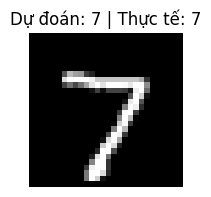

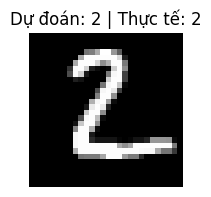

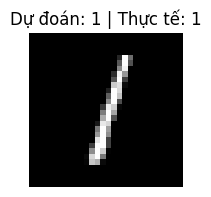

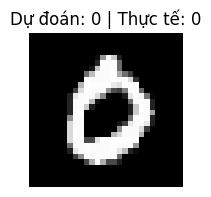

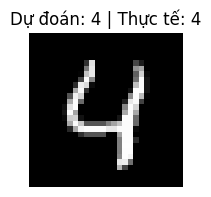

In [ ]:
in_thong_tin()

for image_index in range(5):
    img = np.expand_dims(test_images[image_index], axis=0)   # (1, 28, 28)
    pred = np.argmax(best_model.predict(img, verbose=0), axis=1)[0]

    plt.figure(figsize=(2, 2))
    plt.imshow(test_images[image_index], cmap='gray')
    plt.title(f"Dự đoán: {pred} | Thực tế: {test_labels[image_index]}")
    plt.axis('off')
    plt.show()